# Tugas - Klasifikasi dengan Artificial Neural Network (ANN)

| Nama | NRP |
|------|-----|
| Faiz Farrosian Karim | 5054251027 |

## Deskripsi Tugas
Pada tugas ini, kalian akan membangun model ANN (Multi-Layer Perceptron) Classifier untuk menyelesaikan sebuah masalah klasifikasi.

Dataset dapat diakses melalui link berikut:
[Link dataset akan diinformasikan terpisah]

Tujuan utama dari tugas ini adalah memahami cara kerja ANN secara praktik, khususnya:
1. Perbedaan hasil antar fungsi aktivasi (ReLU, Tanh, Logistic/Sigmoid)
2. Pengaruh ukuran arsitektur (`hidden_layer_sizes`) dan jumlah iterasi terhadap gejala overfitting

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat struktur data, dan distribusi label.
2. Preprocessing
   - Memproses data agar siap digunakan dalam membangun model, termasuk feature scaling.
3. Eksperimen Model
   - Bangun model ANN dengan arsitektur dasar.
   - Lakukan eksperimen fungsi aktivasi dan regularisasi arsitektur.
4. Evaluasi Model
   - Hitung metrik evaluasi dan visualisasikan hasilnya.
5. Analisis dan Kesimpulan
   - Bandingkan hasil eksperimen dan berikan kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, dll)
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report

# supaya output tidak penuh warning konvergensi
warnings.filterwarnings('ignore')

In [2]:
# Load dataset dan tampilkan informasi dasar: jumlah baris dan kolom, tipe data, statistik deskriptif, dan jumlah missing value.
df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')

print('Jumlah baris dan kolom:', df.shape)
print()
df.info()
display(df.head())
display(df.describe())

print('Jumlah missing value per kolom:')
print(df.isnull().sum())

# TotalCharges bertipe object, jadi mungkin ada nilai kosong berupa spasi
print('TotalCharges yang berisi spasi kosong:', (df['TotalCharges'] == ' ').sum())

Jumlah baris dan kolom: (7043, 21)

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling 

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


Jumlah missing value per kolom:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64
TotalCharges yang berisi spasi kosong: 11


Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


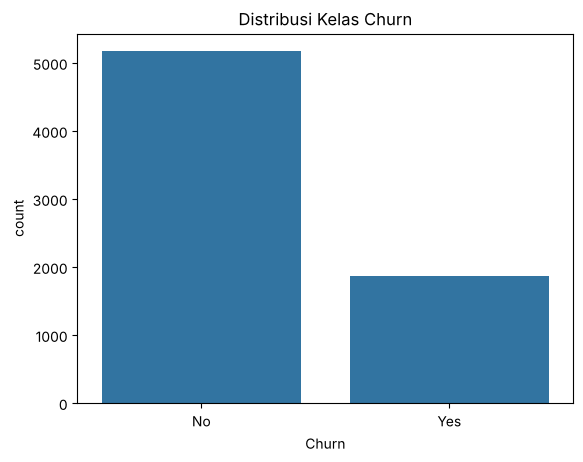

In [3]:
# Tampilkan distribusi kelas target dalam bentuk bar plot.
# Perhatikan apakah dataset ini imbalanced.
print(df['Churn'].value_counts())
print()
print(df['Churn'].value_counts(normalize=True) * 100)

sns.countplot(x='Churn', data=df)
plt.title('Distribusi Kelas Churn')
plt.show()

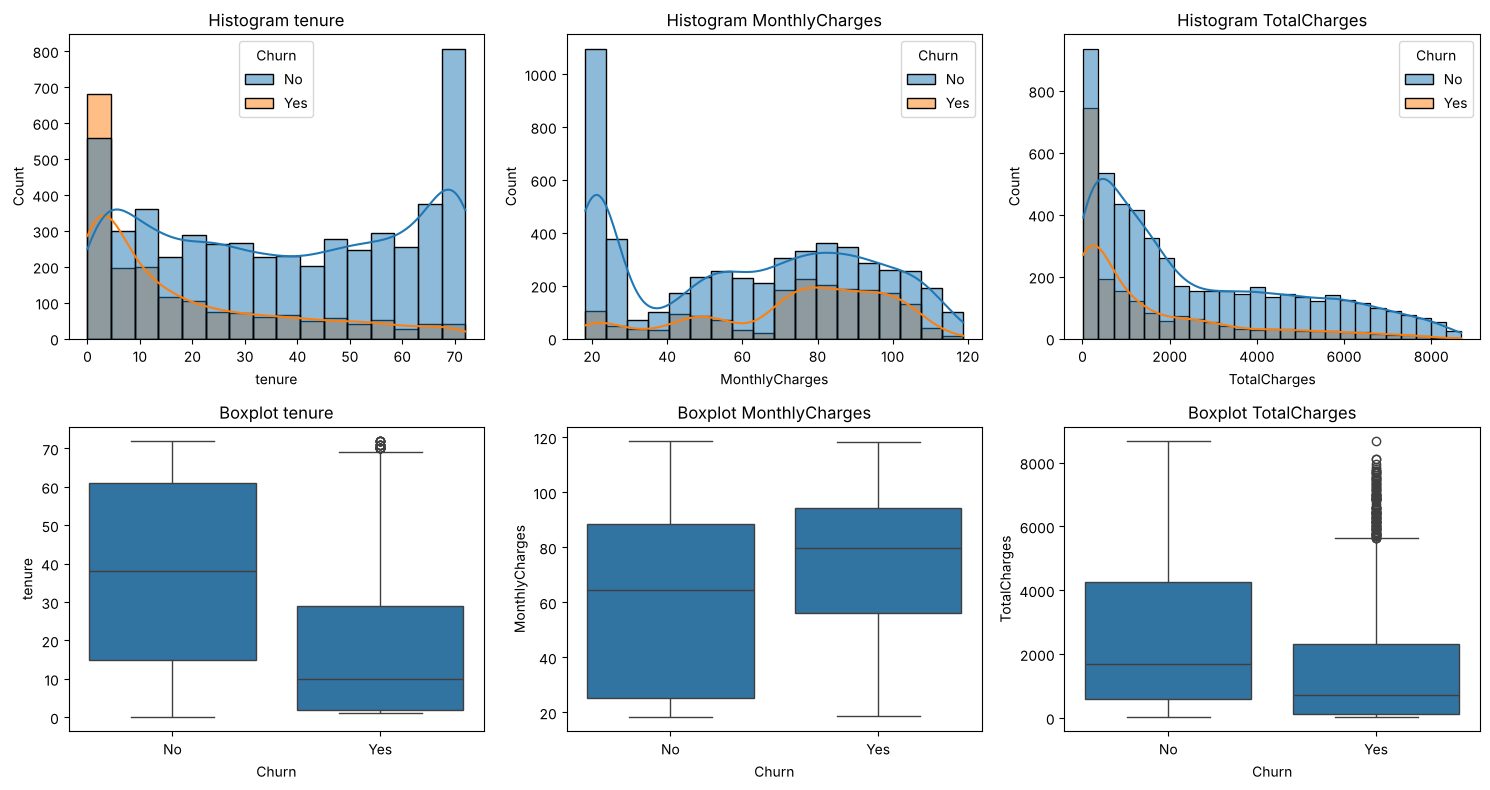

          tenure  MonthlyCharges  TotalCharges
Churn                                         
No     37.569965       61.265124   2555.344141
Yes    17.979133       74.441332   1531.796094


In [4]:
# Tampilkan distribusi atau hubungan antar fitur (histogram, boxplot, atau correlation heatmap), dibedakan berdasarkan kelas target.
# TotalCharges diubah ke angka dulu (khusus untuk EDA)
df_eda = df.copy()
df_eda['TotalCharges'] = pd.to_numeric(df_eda['TotalCharges'], errors='coerce')

kolom_num = ['tenure', 'MonthlyCharges', 'TotalCharges']

plt.figure(figsize=(15, 8))
for i, kolom in enumerate(kolom_num):
    plt.subplot(2, 3, i + 1)
    sns.histplot(data=df_eda, x=kolom, hue='Churn', kde=True)
    plt.title('Histogram ' + kolom)

    plt.subplot(2, 3, i + 4)
    sns.boxplot(data=df_eda, x='Churn', y=kolom)
    plt.title('Boxplot ' + kolom)
plt.tight_layout()
plt.show()

print(df_eda.groupby('Churn')[kolom_num].mean())

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

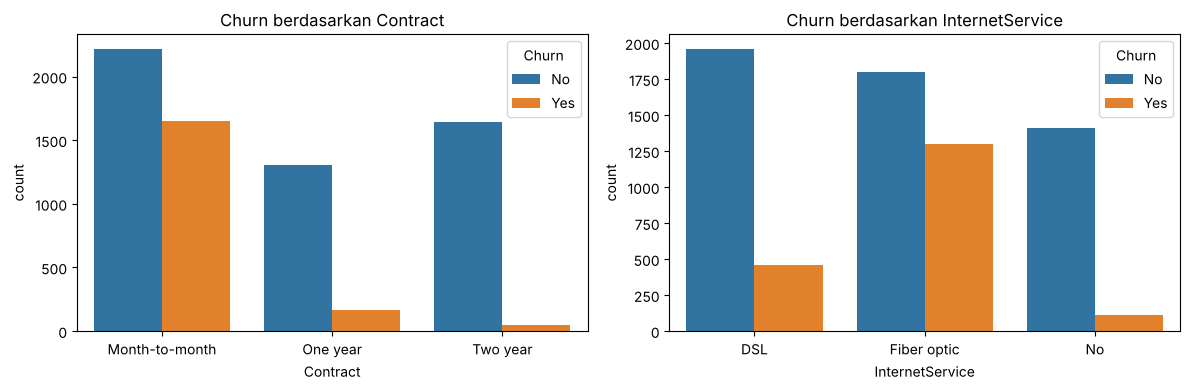

Contract        Churn
Month-to-month  No       57.3
                Yes      42.7
One year        No       88.7
                Yes      11.3
Two year        No       97.2
                Yes       2.8
Name: proportion, dtype: float64


In [5]:
# EDA tambahan: persentase churn berdasarkan jenis kontrak dan layanan internet
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
sns.countplot(x='Contract', hue='Churn', data=df)
plt.title('Churn berdasarkan Contract')

plt.subplot(1, 2, 2)
sns.countplot(x='InternetService', hue='Churn', data=df)
plt.title('Churn berdasarkan InternetService')
plt.tight_layout()
plt.show()

# persentase churn per jenis kontrak
print((df.groupby('Contract')['Churn'].value_counts(normalize=True) * 100).round(1))

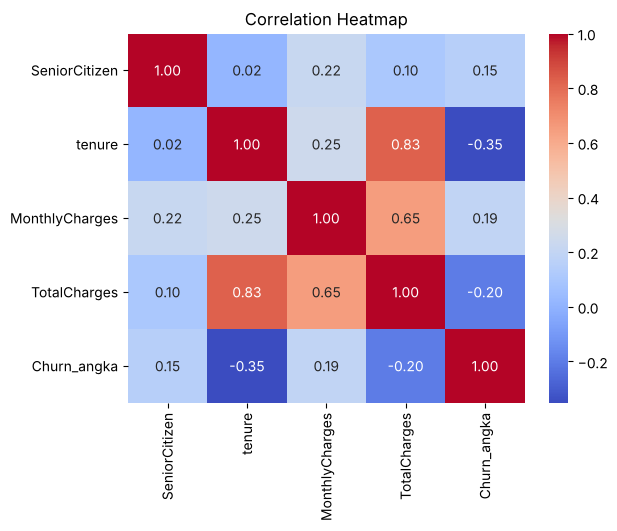

In [6]:
# EDA tambahan: correlation heatmap fitur numerik
df_eda['Churn_angka'] = df_eda['Churn'].map({'No': 0, 'Yes': 1})
korelasi = df_eda[['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn_angka']].corr()

sns.heatmap(korelasi, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

# 2. Preprocessing

In [7]:
# Tangani missing value (jika ada) dengan strategi yang sesuai.
# Pastikan strategi yang dipilih tidak memperkenalkan data leakage.

# ubah TotalCharges ke angka, nilai spasi otomatis jadi NaN
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print('Missing value TotalCharges:', df['TotalCharges'].isnull().sum())

# cek baris yang kosong
display(df[df['TotalCharges'].isnull()][['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges']])

# Semua baris yang kosong punya tenure = 0 (pelanggan baru yang belum pernah ditagih),
# jadi TotalCharges diisi 0. Ini tidak pakai mean/median dari data,
# jadi tidak ada data leakage.
df['TotalCharges'] = df['TotalCharges'].fillna(0)
print('Sisa missing value:', df.isnull().sum().sum())

Missing value TotalCharges: 11


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,NaN
753,3115-CZMZD,0,20.25,NaN
936,5709-LVOEQ,0,80.85,NaN
1082,4367-NUYAO,0,25.75,NaN
1340,1371-DWPAZ,0,56.05,NaN
3331,7644-OMVMY,0,19.85,NaN
3826,3213-VVOLG,0,25.35,NaN
4380,2520-SGTTA,0,20.00,NaN
5218,2923-ARZLG,0,19.70,NaN
6670,4075-WKNIU,0,73.35,NaN


Sisa missing value: 0


In [8]:
# Jika terdapat fitur kategorikal, lakukan encoding yang sesuai (misalnya One-Hot Encoding atau Ordinal Encoding).

# customerID hanya ID unik, tidak berguna untuk prediksi, jadi dibuang
df = df.drop(columns=['customerID'])

# target: Yes = 1, No = 0
df['Churn'] = df['Churn'].map({'No': 0, 'Yes': 1})

# fitur kategorikal -> One-Hot Encoding
kolom_kategori = df.select_dtypes(include=['object', 'string']).columns
print('Kolom kategorikal:', list(kolom_kategori))

df_encoded = pd.get_dummies(df, columns=kolom_kategori, drop_first=True, dtype=int)
print('Bentuk data setelah encoding:', df_encoded.shape)
display(df_encoded.head())

Kolom kategorikal: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Bentuk data setelah encoding: (7043, 31)


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,InternetService_Fiber optic,InternetService_No,OnlineSecurity_No internet service,OnlineSecurity_Yes,OnlineBackup_No internet service,OnlineBackup_Yes,DeviceProtection_No internet service,DeviceProtection_Yes,TechSupport_No internet service,TechSupport_Yes,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,0,1,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,1,0
1,0,34,56.95,1889.50,0,1,0,0,1,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,1
2,0,2,53.85,108.15,1,1,0,0,1,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,1
3,0,45,42.30,1840.75,0,1,0,0,0,1,0,0,0,0,1,0,0,0,1,0,1,0,0,0,0,1,0,0,0,0,0
4,0,2,70.70,151.65,1,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0


In [9]:
# Pisahkan fitur (X) dan target (y).
# Bagi data menjadi train set dan test set (misalnya 80:20).
# Gunakan stratify=y agar distribusi kelas tetap proporsional.
X = df_encoded.drop(columns='Churn')
y = df_encoded['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print('X_train:', X_train.shape)
print('X_test :', X_test.shape)
print('Proporsi churn train:', round(y_train.mean(), 3))
print('Proporsi churn test :', round(y_test.mean(), 3))

X_train: (5634, 30)
X_test : (1409, 30)
Proporsi churn train: 0.265
Proporsi churn test : 0.265


**Catatan penting:** Sama seperti SVM, ANN juga menghitung penjumlahan berbobot dari fitur-fiturnya, sehingga fitur dengan rentang nilai besar bisa mendominasi proses training dan membuat konvergensi lebih lambat atau tidak stabil. Lakukan **feature scaling** (misalnya `StandardScaler`) pada fitur numerik sebelum training. Ingat: `fit` scaler hanya pada train set, lalu `transform` ke train dan test set, agar tidak terjadi data leakage.

In [10]:
# Lakukan feature scaling (StandardScaler) pada fitur numerik.
# fit_transform pada X_train, transform saja pada X_test.
kolom_num = ['tenure', 'MonthlyCharges', 'TotalCharges']

scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[kolom_num] = scaler.fit_transform(X_train[kolom_num])
X_test_scaled[kolom_num] = scaler.transform(X_test[kolom_num])

display(X_train_scaled[kolom_num].describe().round(2))

,tenure,MonthlyCharges,TotalCharges
count,5634.00,5634.00,5634.00
mean,-0.00,-0.00,0.00
std,1.00,1.00,1.00
min,-1.32,-1.54,-1.01
25%,-0.96,-0.97,-0.83
50%,-0.14,0.18,-0.40
75%,0.92,0.83,0.67
max,1.61,1.79,2.80


# 3. Eksperimen Model

## 3.1 ANN dengan Arsitektur Dasar

Bangun model MLPClassifier sederhana dengan satu hidden layer sebagai baseline.

In [11]:
# Inisialisasi dan latih model MLPClassifier dengan satu hidden layer (misalnya hidden_layer_sizes=(10,))
# dan activation='relu' menggunakan train set (yang sudah discaling).
mlp_base = MLPClassifier(hidden_layer_sizes=(10,), activation='relu',
                         max_iter=500, random_state=42)
mlp_base.fit(X_train_scaled, y_train)

print('Jumlah iterasi yang dipakai:', mlp_base.n_iter_)
print('Loss akhir:', round(mlp_base.loss_, 4))

Jumlah iterasi yang dipakai: 326
Loss akhir: 0.3934


In [12]:
# Lakukan prediksi pada test set.
# Simpan hasil prediksi label untuk keperluan evaluasi.
y_pred_base = mlp_base.predict(X_test_scaled)

print('Akurasi train:', round(mlp_base.score(X_train_scaled, y_train), 4))
print('Akurasi test :', round(accuracy_score(y_test, y_pred_base), 4))
print('10 prediksi pertama:', y_pred_base[:10])

Akurasi train: 0.817
Akurasi test : 0.797
10 prediksi pertama: [0 1 0 0 0 1 0 0 0 0]


## 3.2 Eksperimen Fungsi Aktivasi

Fungsi aktivasi menentukan bagaimana neuron "mengaktivasikan" keluarannya dan memungkinkan model mempelajari pola non-linear. Bandingkan beberapa pilihan fungsi aktivasi yang tersedia di scikit-learn.

In [13]:
# Latih beberapa model MLPClassifier dengan arsitektur yang sama, tetapi activation berbeda:
# 'relu', 'tanh', dan 'logistic'.
# Gunakan hyperparameter lain yang sama (hidden_layer_sizes, max_iter, random_state) agar perbandingan adil.
daftar_aktivasi = ['relu', 'tanh', 'logistic']
model_aktivasi = {}

for akt in daftar_aktivasi:
    model = MLPClassifier(hidden_layer_sizes=(10,), activation=akt,
                          max_iter=500, random_state=42)
    model.fit(X_train_scaled, y_train)
    model_aktivasi[akt] = model
    print('Selesai melatih activation =', akt)

Selesai melatih activation = relu
Selesai melatih activation = tanh
Selesai melatih activation = logistic


In [14]:
# Hitung dan bandingkan akurasi test set dari ketiga fungsi aktivasi tersebut.
# Sajikan dalam tabel perbandingan.
hasil_aktivasi = []
for akt in daftar_aktivasi:
    model = model_aktivasi[akt]
    hasil_aktivasi.append({
        'Activation': akt,
        'Akurasi Train': model.score(X_train_scaled, y_train),
        'Akurasi Test': model.score(X_test_scaled, y_test),
        'Iterasi': model.n_iter_,
        'Loss Akhir': model.loss_
    })

tabel_aktivasi = pd.DataFrame(hasil_aktivasi)
display(tabel_aktivasi.round(4))

# activation terbaik = akurasi test tertinggi
best_act = tabel_aktivasi.loc[tabel_aktivasi['Akurasi Test'].idxmax(), 'Activation']
print('Activation terbaik:', best_act)

,Activation,Akurasi Train,Akurasi Test,Iterasi,Loss Akhir
0,relu,0.8170,0.7970,326,0.3934
1,tanh,0.8225,0.7864,500,0.3879
2,logistic,0.8062,0.8013,153,0.4113


Activation terbaik: logistic


## 3.3 Eksperimen Regularisasi: Pengaruh Ukuran Arsitektur terhadap Overfitting

Semakin besar/dalam arsitektur ANN (jumlah neuron dan hidden layer), semakin besar kapasitas model untuk menghafal data training. Pada bagian ini kalian akan mengamati bagaimana perubahan ukuran arsitektur memengaruhi akurasi training dan testing.

In [15]:
# Latih beberapa model MLPClassifier dengan variasi hidden_layer_sizes,
# misalnya (2,), (5,), (10,), (50,), (100, 50).
# Gunakan activation terbaik dari hasil eksperimen 3.2, dan hyperparameter lain yang sama.
daftar_arsitektur = [(2,), (5,), (10,), (50,), (100, 50)]
model_arsitektur = {}

for arsitektur in daftar_arsitektur:
    model = MLPClassifier(hidden_layer_sizes=arsitektur, activation=best_act,
                          max_iter=500, random_state=42)
    model.fit(X_train_scaled, y_train)
    model_arsitektur[arsitektur] = model
    print('Selesai melatih arsitektur', arsitektur)

Selesai melatih arsitektur (2,)
Selesai melatih arsitektur (5,)
Selesai melatih arsitektur (10,)
Selesai melatih arsitektur (50,)
Selesai melatih arsitektur (100, 50)


In [16]:
# Hitung akurasi pada train set dan test set untuk setiap arsitektur yang dicoba.
# Simpan hasilnya dalam list atau dictionary agar mudah diplot.
hasil_arsitektur = []
for arsitektur in daftar_arsitektur:
    model = model_arsitektur[arsitektur]
    acc_train = model.score(X_train_scaled, y_train)
    acc_test = model.score(X_test_scaled, y_test)
    hasil_arsitektur.append({
        'Arsitektur': str(arsitektur),
        'Akurasi Train': acc_train,
        'Akurasi Test': acc_test,
        'Selisih (Train - Test)': acc_train - acc_test,
        'Iterasi': model.n_iter_
    })

tabel_arsitektur = pd.DataFrame(hasil_arsitektur)
display(tabel_arsitektur.round(4))

,Arsitektur,Akurasi Train,Akurasi Test,Selisih (Train - Test),Iterasi
0,"(2,)",0.8033,0.7991,0.0042,195
1,"(5,)",0.8069,0.7977,0.0092,211
2,"(10,)",0.8062,0.8013,0.0049,153
3,"(50,)",0.8072,0.8062,0.0010,154
4,"(100, 50)",0.8064,0.8034,0.0029,115


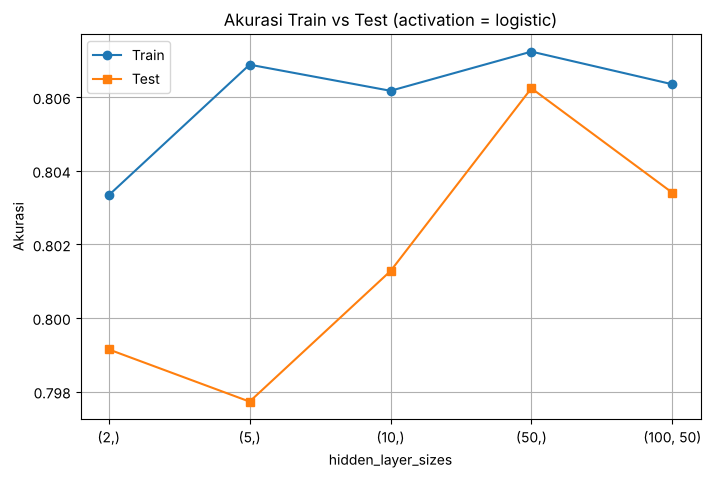

In [17]:
# Plot grafik akurasi training vs testing terhadap ukuran arsitektur dalam satu chart.
# Amati pada arsitektur seberapa besar model mulai menunjukkan gejala overfitting
# (akurasi training terus naik, sementara akurasi testing mulai stagnan atau menurun).
plt.figure(figsize=(8, 5))
plt.plot(tabel_arsitektur['Arsitektur'], tabel_arsitektur['Akurasi Train'], marker='o', label='Train')
plt.plot(tabel_arsitektur['Arsitektur'], tabel_arsitektur['Akurasi Test'], marker='s', label='Test')
plt.title('Akurasi Train vs Test (activation = ' + best_act + ')')
plt.xlabel('hidden_layer_sizes')
plt.ylabel('Akurasi')
plt.legend()
plt.grid(True)
plt.show()

,Arsitektur,Akurasi Train,Akurasi Test,Selisih (Train - Test)
0,"(2,)",0.8060,0.7977,0.0083
1,"(5,)",0.8080,0.7999,0.0081
2,"(10,)",0.8170,0.7970,0.0200
3,"(50,)",0.8346,0.7842,0.0503
4,"(100, 50)",0.9526,0.7445,0.2081


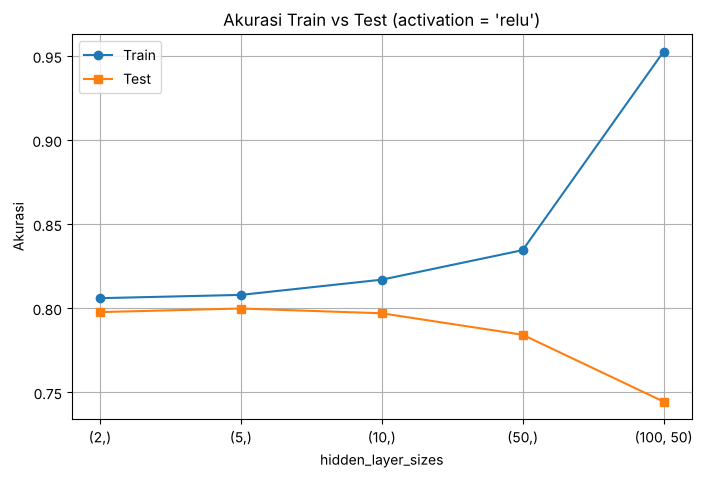

In [18]:
# Eksperimen tambahan: ulangi eksperimen arsitektur dengan activation 'relu'
# (untuk melihat apakah activation lain lebih mudah overfitting)
hasil_relu = []
for arsitektur in daftar_arsitektur:
    model = MLPClassifier(hidden_layer_sizes=arsitektur, activation='relu',
                          max_iter=500, random_state=42)
    model.fit(X_train_scaled, y_train)
    acc_train = model.score(X_train_scaled, y_train)
    acc_test = model.score(X_test_scaled, y_test)
    hasil_relu.append({
        'Arsitektur': str(arsitektur),
        'Akurasi Train': acc_train,
        'Akurasi Test': acc_test,
        'Selisih (Train - Test)': acc_train - acc_test
    })

tabel_relu = pd.DataFrame(hasil_relu)
display(tabel_relu.round(4))

plt.figure(figsize=(8, 5))
plt.plot(tabel_relu['Arsitektur'], tabel_relu['Akurasi Train'], marker='o', label='Train')
plt.plot(tabel_relu['Arsitektur'], tabel_relu['Akurasi Test'], marker='s', label='Test')
plt.title("Akurasi Train vs Test (activation = 'relu')")
plt.xlabel('hidden_layer_sizes')
plt.ylabel('Akurasi')
plt.legend()
plt.grid(True)
plt.show()

,max_iter,Iterasi Aktual,Akurasi Train,Akurasi Test
0,10,10,0.8151,0.7970
1,25,25,0.8236,0.7821
2,50,50,0.8426,0.7800
3,100,100,0.8825,0.7736
4,200,200,0.9175,0.7622
5,500,349,0.9526,0.7445


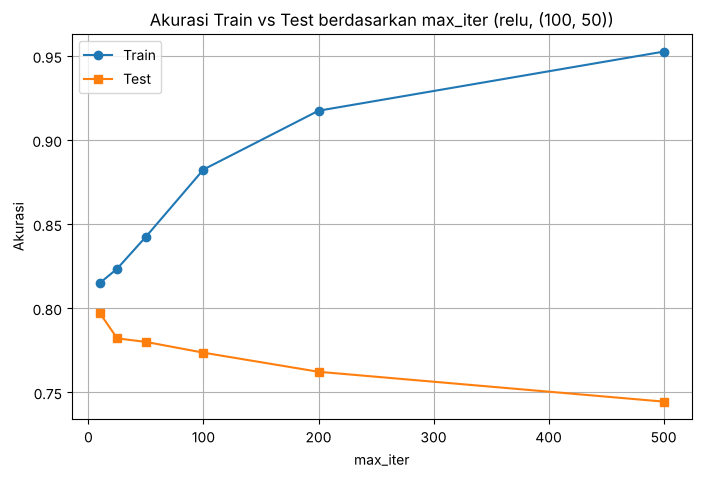

In [19]:
# Eksperimen tambahan: pengaruh max_iter (jumlah iterasi) pada arsitektur besar (100, 50)
daftar_iter = [10, 25, 50, 100, 200, 500]
hasil_iter = []
for it in daftar_iter:
    model = MLPClassifier(hidden_layer_sizes=(100, 50), activation='relu',
                          max_iter=it, random_state=42)
    model.fit(X_train_scaled, y_train)
    hasil_iter.append({
        'max_iter': it,
        'Iterasi Aktual': model.n_iter_,
        'Akurasi Train': model.score(X_train_scaled, y_train),
        'Akurasi Test': model.score(X_test_scaled, y_test)
    })

tabel_iter = pd.DataFrame(hasil_iter)
display(tabel_iter.round(4))

plt.figure(figsize=(8, 5))
plt.plot(tabel_iter['max_iter'], tabel_iter['Akurasi Train'], marker='o', label='Train')
plt.plot(tabel_iter['max_iter'], tabel_iter['Akurasi Test'], marker='s', label='Test')
plt.title("Akurasi Train vs Test berdasarkan max_iter (relu, (100, 50))")
plt.xlabel('max_iter')
plt.ylabel('Akurasi')
plt.legend()
plt.grid(True)
plt.show()

# 4. Evaluasi Model

In [20]:
# Tampilkan metrik evaluasi (Accuracy, Precision, Recall, F1-Score) untuk model dengan performa terbaik dari tiap eksperimen (3.2 dan 3.3).
# Sajikan dalam satu tabel perbandingan agar mudah dibandingkan.
# Kelas positif = Churn (1)

# model terbaik 3.2
model_32 = model_aktivasi[best_act]

# model terbaik 3.3 (akurasi test tertinggi)
idx_terbaik = tabel_arsitektur['Akurasi Test'].idxmax()
arsitektur_terbaik = daftar_arsitektur[idx_terbaik]
model_33 = model_arsitektur[arsitektur_terbaik]

nama_model = ['Eksperimen 3.2: ' + best_act + ', (10,)',
              'Eksperimen 3.3: ' + best_act + ', ' + str(arsitektur_terbaik)]
list_model = [model_32, model_33]

hasil_metrik = []
for nama, model in zip(nama_model, list_model):
    y_pred = model.predict(X_test_scaled)
    hasil_metrik.append({
        'Model': nama,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1-Score': f1_score(y_test, y_pred)
    })

tabel_metrik = pd.DataFrame(hasil_metrik)
display(tabel_metrik.round(4))

# model terbaik keseluruhan = akurasi tertinggi
idx_best = tabel_metrik['Accuracy'].idxmax()
best_model = list_model[idx_best]
best_name = nama_model[idx_best]
print('Model terbaik:', best_name)
print()
print(classification_report(y_test, best_model.predict(X_test_scaled),
                            target_names=['No Churn', 'Churn']))

,Model,Accuracy,Precision,Recall,F1-Score
0,"Eksperimen 3.2: logistic, (10,)",0.8013,0.6516,0.5401,0.5906
1,"Eksperimen 3.3: logistic, (50,)",0.8062,0.6624,0.5508,0.6015


Model terbaik: Eksperimen 3.3: logistic, (50,)

              precision    recall  f1-score   support

    No Churn       0.85      0.90      0.87      1035
       Churn       0.66      0.55      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.72      0.74      1409
weighted avg       0.80      0.81      0.80      1409



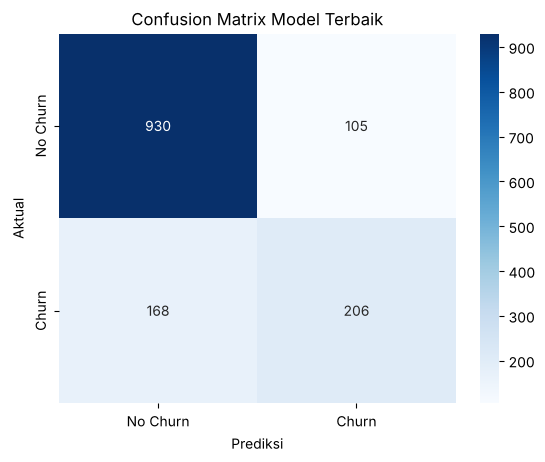

TN = 930 | FP = 105 | FN = 168 | TP = 206


In [21]:
# Tampilkan Confusion Matrix untuk model dengan performa terbaik dalam bentuk heatmap.
y_pred_best = best_model.predict(X_test_scaled)
cm = confusion_matrix(y_test, y_pred_best)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Churn', 'Churn'], yticklabels=['No Churn', 'Churn'])
plt.title('Confusion Matrix Model Terbaik')
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.show()

tn, fp, fn, tp = cm.ravel()
print('TN =', tn, '| FP =', fp, '| FN =', fn, '| TP =', tp)

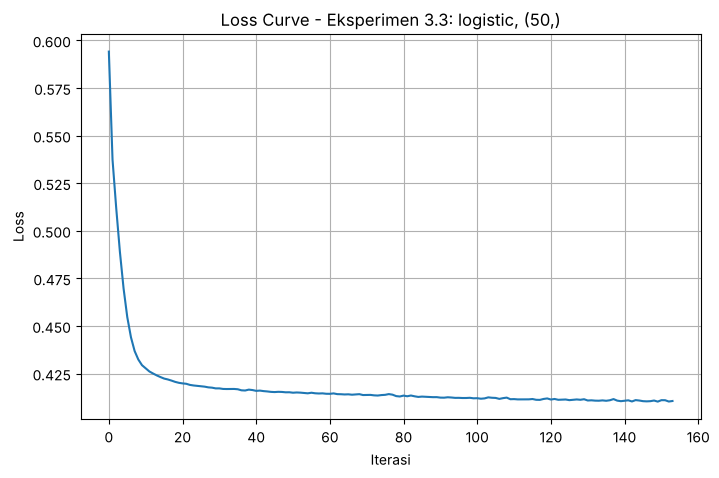

Iterasi aktual: 154 dari max_iter = 500
Loss awal: 0.5941
Loss akhir: 0.4106


In [22]:
# Plot loss curve dari model dengan performa terbaik (atribut model.loss_curve_).
# Amati apakah loss sudah konvergen atau masih menurun saat max_iter tercapai.
plt.figure(figsize=(8, 5))
plt.plot(best_model.loss_curve_)
plt.title('Loss Curve - ' + best_name)
plt.xlabel('Iterasi')
plt.ylabel('Loss')
plt.grid(True)
plt.show()

print('Iterasi aktual:', best_model.n_iter_, 'dari max_iter =', best_model.max_iter)
print('Loss awal:', round(best_model.loss_curve_[0], 4))
print('Loss akhir:', round(best_model.loss_curve_[-1], 4))

# 5. Analisis

### Jelaskan secara detail hasil analisis yang didapatkan dari eksperimen yang telah dilakukan.

Beberapa hal yang perlu dibahas:
- Bandingkan performa ANN dengan fungsi aktivasi ReLU, Tanh, dan Logistic. Apakah hasilnya berbeda signifikan? Menurut kalian, kenapa demikian?
- Jelaskan temuan dari eksperimen regularisasi (ukuran arsitektur). Pada ukuran arsitektur berapa model mulai menunjukkan gejala overfitting? Bagaimana ciri-cirinya terlihat dari grafik akurasi training vs testing?
- Berdasarkan loss curve yang dihasilkan, apakah model sudah cukup konvergen? Apa yang akan kalian lakukan jika loss curve masih menurun tajam saat max_iter tercapai?

Pastikan analisis didasari oleh hasil eksperimen sendiri yang telah dilakukan, bukan hasil orang lain.

## Hasil Analisis

**Dataset.** Dataset yang dipakai adalah Telco Customer Churn (7043 pelanggan, target `Churn`). Kelasnya imbalanced: sekitar 73,5% tidak churn dan 26,5% churn (rasio sekitar 2,77 : 1). Karena itu akurasi saja kurang cukup untuk menilai model, jadi Precision, Recall, dan F1 juga dilihat. Dari EDA, pelanggan yang churn rata-rata punya `tenure` lebih pendek (sekitar 18 bulan, dibanding 37,6 bulan pada yang tidak churn) dan `MonthlyCharges` lebih tinggi (sekitar 74,4 dibanding 61,3).

**1. Perbandingan fungsi aktivasi (arsitektur (10,), max_iter = 500)**

| Activation | Akurasi Train | Akurasi Test | Iterasi |
|---|---|---|---|
| relu | 0,8170 | 0,7970 | 326 |
| tanh | 0,8225 | 0,7864 | 500 (belum konvergen) |
| logistic | 0,8062 | 0,8013 | 153 |

Akurasi test tertinggi didapat oleh `logistic` (0,8013), tapi selisihnya dengan `relu` (0,7970) hanya sekitar 0,4%, dan dengan `tanh` sekitar 1,5%. Menurut saya perbedaan ini **tidak signifikan**. Dengan 1409 data test, selisih 0,4% itu cuma sekitar 6 data, dan hasilnya bisa saja berubah kalau `random_state` diganti karena bobot awal MLP diacak. Jadi dari eksperimen ini saya tidak bisa bilang `logistic` pasti paling bagus, hanya bahwa pada satu kali run ini dia paling tinggi.

Kemungkinan penyebabnya: ketiga fungsi aktivasi sama-sama bisa membuat model non-linear, dan dengan hanya 10 neuron serta data tabular yang sederhana, hasilnya mirip. Ada satu hal yang berbeda, yaitu `logistic` berhenti lebih cepat (153 iterasi) dan akurasi train-nya paling rendah, jadi dia paling "tidak menghafal". `tanh` dan `relu` punya akurasi train lebih tinggi tapi akurasi test-nya lebih rendah, yang artinya sedikit lebih mudah menghafal data train. `tanh` juga sampai 500 iterasi dan belum konvergen.

**2. Pengaruh ukuran arsitektur terhadap overfitting**

Pada eksperimen 3.3 (activation `logistic`), hasilnya hampir datar:

| Arsitektur | Akurasi Train | Akurasi Test | Selisih |
|---|---|---|---|
| (2,) | 0,8033 | 0,7991 | 0,0042 |
| (5,) | 0,8069 | 0,7977 | 0,0092 |
| (10,) | 0,8062 | 0,8013 | 0,0049 |
| (50,) | 0,8072 | 0,8062 | 0,0010 |
| (100, 50) | 0,8064 | 0,8034 | 0,0029 |

Pada `logistic`, **tidak terlihat overfitting** sampai arsitektur (100, 50). Akurasi train dan test sama-sama sekitar 0,80 dan selisihnya kecil. Menambah neuron dari 2 sampai 100x50 juga hampir tidak menaikkan akurasi, jadi model kecil (2 neuron) sudah cukup untuk dataset ini.

Karena itu saya mencoba eksperimen tambahan dengan `relu`:

| Arsitektur | Akurasi Train | Akurasi Test | Selisih |
|---|---|---|---|
| (2,) | 0,8060 | 0,7977 | 0,0083 |
| (5,) | 0,8080 | 0,7999 | 0,0081 |
| (10,) | 0,8170 | 0,7970 | 0,0200 |
| (50,) | 0,8346 | 0,7842 | 0,0503 |
| (100, 50) | 0,9526 | 0,7445 | 0,2081 |

Di sini gejala overfitting terlihat jelas. Mulai dari (10,) akurasi train naik terus sementara akurasi test turun, dan pada (50,) selisihnya sudah sekitar 5%. Pada (100, 50) akurasi train mencapai 95,3% tetapi akurasi test turun ke 74,5%, selisihnya sekitar 21%. Ciri overfitting di grafik: garis train terus naik sedangkan garis test justru turun, sehingga jarak kedua garis makin lebar. Jadi pada `relu` overfitting mulai terlihat di arsitektur sekitar (50,) dan sangat jelas di (100, 50).

**3. Pengaruh jumlah iterasi (max_iter)**

Pada `relu` dengan arsitektur (100, 50), makin besar `max_iter` makin besar juga overfitting-nya. Dengan `max_iter` = 10, akurasi train 0,8151 dan test 0,7970. Saat `max_iter` = 200, train naik ke 0,9175 dan test turun ke 0,7622. Pada `max_iter` = 500 (berhenti di iterasi ke-349) train 0,9526 dan test 0,7445. Jadi semakin lama dilatih, model makin menghafal data train dan makin buruk di data test.

**4. Loss curve**

Model terbaik (`logistic`, (50,)) berhenti di iterasi ke-154 dari `max_iter` = 500, jadi berhenti karena kriteria konvergensi (loss tidak membaik lagi), bukan karena batas iterasi. Loss turun dari 0,5941 di awal menjadi 0,4106, dan kurvanya sudah mendatar di akhir. Artinya model sudah cukup konvergen. Kalau suatu saat loss curve masih turun tajam saat `max_iter` tercapai (kemungkinan terjadi pada `tanh` yang sampai 500 iterasi), yang akan saya lakukan adalah menaikkan `max_iter`, lalu memeriksa lagi akurasi train vs test supaya tidak overfitting. Opsi lain adalah menaikkan learning rate atau memakai solver lain.

**5. Evaluasi model terbaik**

Model terbaik adalah `logistic` dengan (50,): Accuracy 0,8062, Precision 0,6624, Recall 0,5508, F1 0,6015. Dari confusion matrix: TN = 930, FP = 105, FN = 168, TP = 206. Dari 374 pelanggan yang benar-benar churn, hanya 206 yang terdeteksi dan 168 terlewat. Model bagus memprediksi pelanggan yang tidak churn (recall 0,90) tapi kurang bagus mendeteksi yang churn (recall 0,55), kemungkinan karena data imbalanced.

# 6. Kesimpulan dan Saran

### Berikan kesimpulan dari eksperimen yang telah dilakukan.

Saran dapat berupa rekomendasi untuk eksperimen selanjutnya (misalnya mencoba solver lain seperti 'sgd', menambahkan regularisasi alpha, melakukan hyperparameter tuning dengan GridSearchCV, atau membandingkan dengan model lain), perbaikan model, atau hal-hal lain yang relevan dengan tugas ini.

## Kesimpulan

1. Fungsi aktivasi `logistic` memberi akurasi test tertinggi (0,8013), diikuti `relu` (0,7970) dan `tanh` (0,7864). Selisihnya kecil, jadi pada dataset ini pilihan fungsi aktivasi tidak berpengaruh besar terhadap akurasi test.
2. Ukuran arsitektur berpengaruh terhadap overfitting, tapi tergantung fungsi aktivasi. Pada `logistic` tidak ada overfitting yang jelas sampai (100, 50), sedangkan pada `relu` overfitting mulai terlihat di (50,) dan sangat jelas di (100, 50) (train 0,9526 vs test 0,7445).
3. Jumlah iterasi juga berpengaruh. Makin besar `max_iter` pada arsitektur besar, akurasi train naik terus sementara akurasi test turun.
4. Model terbaik adalah `logistic` dengan (50,): akurasi 0,8062 dan F1 0,6015. Loss-nya sudah konvergen (berhenti di iterasi ke-154 dari 500).
5. Model masih lemah dalam mendeteksi pelanggan yang churn (recall 0,55), padahal itu kelas yang paling penting untuk bisnis. Akurasi sekitar 80% juga sebenarnya tidak jauh dari tebakan "semua tidak churn" (sekitar 73,5%).

## Saran

- Mencoba `class_weight` atau teknik penyeimbang data (misalnya SMOTE) karena data imbalanced. Catatan: `MLPClassifier` tidak punya parameter `class_weight`, jadi bisa lewat oversampling.
- Menambahkan regularisasi `alpha` atau `early_stopping=True` untuk mengurangi overfitting pada arsitektur besar.
- Melakukan hyperparameter tuning dengan `GridSearchCV`, dan mengulang eksperimen dengan beberapa `random_state` supaya perbandingan fungsi aktivasi lebih meyakinkan.
- Mencoba solver lain seperti `sgd`, atau membandingkan dengan model lain (Logistic Regression, Random Forest, SVM).
- Melihat metrik Recall dan F1 untuk kelas churn, bukan hanya akurasi.